# 03 · Evaluación, diagnósticos y conclusiones

Contrastamos las recetas elegidas, comprobamos los pesos por temporada y examinamos dónde fallan.
Separar magnitud, dirección y variabilidad del error ayuda a valorar la utilidad del predictor.
Los diagnósticos no se utilizan para elegir después un modelo distinto para cada club.

**Captura del estudio:** 20 de octubre de 2026, temporada **2026/27 hasta J9**: **88 partidos
finalizados**. El desarrollo utiliza los **59 de las jornadas 1–6**; los **29 restantes** forman
el contraste temporal. El análisis es retrospectivo: este contraste no se presenta como un test
ciego independiente de toda la exploración. Los recuentos reales se muestran al cargar los datos.

**Distribución pública.** Se conservan las explicaciones y los resultados agregados del estudio. Los CSV reales y las salidas de partidos individuales no se incluyen. Para ejecutar las celdas, prepara primero tus datos en `data/local/actualizados` siguiendo [docs/guia_de_uso.md](../docs/guia_de_uso.md). Obtener otra captura no garantiza las mismas métricas.


In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
RAIZ = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
assert (RAIZ/"src/faltas").is_dir(), "Abre el notebook desde la carpeta del proyecto o notebooks/."
sys.path.insert(0, str(RAIZ/"src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from faltas.util import leer_json
from faltas.datos import datos_por_defecto, cargar_datos
from faltas.investigacion.biblioteca import tabla, mostrar, imagen, resumen_hipotesis
from faltas.entrega import cobertura, INFORMES_ACTUALES
get_ipython().run_line_magic("matplotlib", "inline")
CARPETA_ACTUALIZADA = RAIZ/"data/local/actualizados"
DATOS = (datos_por_defecto() if os.environ.get("FALTAS_DATOS") else
         CARPETA_ACTUALIZADA if CARPETA_ACTUALIZADA.exists() else datos_por_defecto())
d = cargar_datos(DATOS)
INFO_DATOS = cobertura(d)
print("Carpeta de datos elegida:", DATOS.relative_to(RAIZ) if DATOS.is_relative_to(RAIZ) else DATOS)
print("Captura:", INFO_DATOS["captura_utc"], "| Hasta jornada:", INFO_DATOS["jornada_hasta"])
print("Partidos actuales:", INFO_DATOS["partidos_actuales"], "| Historial finalizado:", INFO_DATOS["partidos_finalizados"])
INFORMES = RAIZ/"reports/investigacion"
if d.huella != leer_json(RAIZ/"config/diseno_estudio.json")["huella_datos"]:
    print("Los CSV elegidos difieren de la captura del estudio: las tablas archivadas siguen siendo V1 hasta J9.")
from faltas.entrega import preparar_actualizacion, COMBINADA
entrega=preparar_actualizacion(DATOS)
e_actual=entrega["estudio"]
pred_actuales=entrega["predicciones"]
diag_actual=entrega["diagnosticos"]
exp_actual=entrega["explicaciones"]
def figura_actual(nombre):
    display(Image(filename=str(entrega["carpeta_figuras"]/nombre)))
mostrar("Captura y política evaluadas",pd.DataFrame([entrega["info"]]))

Carpeta de datos elegida: data\local\estudio_v1
Captura: 2026-10-20T10:36:55Z | Hasta jornada: 9
Partidos actuales: 88 | Historial finalizado: 1228


captura_utc,temporada,partidos_finalizados,partidos_actuales,jornada_hasta,partidos_actuales_registrados,pendientes_anteriores,programados,ultimo_inicio_finalizado_utc,huella_datos,modelo_recomendado,nombre_recomendado,fecha_evaluacion_utc,recetas_fijas,nuevo_test_independiente,politica,desarrollo_partidos,contraste_partidos,alcance,test_independiente
2026-10-20T10:36:55Z,2026/27,1228,88,9,100,2,10,2026-10-19T19:00:32+00:00,8b57ad5c8f220b0669096f213d13246dfd91aad0c0be22d448072a699c0125d0,grid_global93_030,XGBoost global (93),2026-10-20T15:48:03.878861+00:00,True,False,"{'masas_temporadas': [0.35, 0.35, 0.2, 0.1], 'semivida_dias': 90}",59,29,Estudio retrospectivo unificado hasta J9,False


<a id="test"></a>
## 1. Contraste temporal con configuraciones fijadas

Comparamos las tres recetas con sus candidatos previos y las cuatro referencias, con
el reparto inicial 55/25/13/7. Se muestran desarrollo, los 29
partidos posteriores y el acumulado de 88. Cada previsión se hizo fuera de su propio entrenamiento.
Este contraste retrospectivo no es un test ciego de todo el proceso: se han revisado repetidamente
los resultados. Las configuraciones permanecen fijas durante cada recorrido temporal.

In [2]:
mostrar("Contraste de ocho métodos y controles: equipo, localía y total",tabla("contraste","metricas.csv"),abierto=True)
mostrar("Frecuencia de errores pequeños y grandes",tabla("contraste","precision.csv"))
t=tabla("contraste","metricas.csv")
print("Menor RMSE del contraste temporal con pesos iniciales:",t.loc[t.muestra.eq("Contraste temporal")&t.nivel.eq("Equipo")].sort_values(["RMSE","MAE"]).iloc[0].modelo)

modelo,periodo,nivel,partidos,n,RMSE,MAE,sesgo,muestra
media_global_uniforme,2026/27,Equipo,59,118,3.97908,3.23373,0.265414,Desarrollo
media_global_uniforme,2026/27,Local,59,59,3.95432,3.40693,0.0874482,Desarrollo
media_global_uniforme,2026/27,Visitante,59,59,4.00369,3.06053,0.44338,Desarrollo
media_global_uniforme,2026/27,Total partido,59,59,6.00227,4.88213,0.530829,Desarrollo
media_global_recencia,2026/27,Equipo,59,118,3.98411,3.25687,0.38684,Desarrollo
media_global_recencia,2026/27,Local,59,59,3.92099,3.37912,0.208874,Desarrollo
media_global_recencia,2026/27,Visitante,59,59,4.04625,3.13462,0.564806,Desarrollo
media_global_recencia,2026/27,Total partido,59,59,6.01561,4.87415,0.77368,Desarrollo
liga_localia_previa,2026/27,Equipo,59,118,3.99055,3.23701,0.38684,Desarrollo
liga_localia_previa,2026/27,Local,59,59,3.97332,3.42312,0.462455,Desarrollo


modelo,partidos,n,error_hasta2_pct,error_hasta3_pct,error_desde5_pct,max_error_absoluto,correlacion,desv_prediccion,desv_observada,muestra
media_global_uniforme,59,118,38.1356,50,18.6441,11.3714,-0.0154272,0.0097963,3.98699,Desarrollo
media_global_recencia,59,118,35.5932,50,19.4915,11.6533,0.0634947,0.414145,3.98699,Desarrollo
liga_localia_previa,59,118,38.1356,50,19.4915,11.8038,0.06747,0.56226,3.98699,Desarrollo
equipo_rival_previo,59,118,42.3729,57.6271,21.1864,11.3669,0.275804,1.32974,3.98699,Desarrollo
xgb_poisson_sin_grupos,59,118,41.5254,53.3898,16.9492,11.8344,0.336648,1.65758,3.98699,Desarrollo
local_perfil_directos,59,118,40.678,57.6271,21.1864,10.8062,0.361657,2.1413,3.98699,Desarrollo
grid_global93_030,59,118,41.5254,55.9322,16.9492,11.5908,0.33993,1.6516,3.98699,Desarrollo
grid_pareja29_equilibrada_024,59,118,44.0678,55.9322,21.1864,12.1629,0.402709,2.34173,3.98699,Desarrollo
media_global_uniforme,29,58,39.6552,55.1724,17.2414,8.62735,-0.0590561,0.0031848,3.81023,Contraste temporal
media_global_recencia,29,58,39.6552,55.1724,17.2414,8.58569,-0.163111,0.0269645,3.81023,Contraste temporal


Menor RMSE del contraste temporal con pesos iniciales: equipo_rival_previo


**Lectura del contraste.** Con 55/25/13/7, equipo/rival obtiene MAE 2,7806 y RMSE 3,5810; el global, 2,8918 y 3,7341; la pareja, 3,2202 y 4,1330. La referencia lidera esos 29 encuentros. El siguiente bloque comprueba otros repartos de temporada, manteniendo las recetas.

<a id="pesos"></a>
## 2. Nueve repartos de peso entre temporadas

Comparamos nueve repartos en total, incluido el inicial 55/25/13/7, con las recetas XGBoost fijadas.
Para mantener un reparto común se ordena la media del RMSE de los tres métodos en desarrollo.
Se muestran también sus mejores repartos individuales y lo que ocurre después. Esta búsqueda
forma parte de la exploración y no convierte el contraste en independiente.

In [3]:
pol=leer_json(RAIZ/"config/experimentos/experimento_pesos.json")
mostrar("Nueve políticas y motivación",pd.DataFrame(pol["politicas"]))
pesos=tabla("pesos","metricas.csv")
mostrar("Todas las políticas: tres métodos y tres muestras",pesos)
seleccion=tabla("pesos","seleccion.csv")
mostrar("Reparto común: orden de desarrollo y comportamiento posterior",seleccion,abierto=True)
assert seleccion.iloc[0].politica=="p35_35_20_10"
mostrar("Mejores individuales de desarrollo: se documentan, sin adoptarlos",tabla("pesos","mejores_individuales.csv"))

id,masas_temporadas,motivo
p55_25_13_07,"[0.55, 0.25, 0.13, 0.07]",Control original: mayoría actual.
p50_30_12_08,"[0.5, 0.3, 0.12, 0.08]",Reducir la diferencia entre actual y anterior.
p45_30_15_10,"[0.45, 0.3, 0.15, 0.1]",Transición moderada con más apoyo antiguo.
p40_35_15_10,"[0.4, 0.35, 0.15, 0.1]",Actual y anterior próximas; 25% para las dos antiguas.
p40_30_20_10,"[0.4, 0.3, 0.2, 0.1]",Descenso regular entre temporadas.
p35_35_20_10,"[0.35, 0.35, 0.2, 0.1]",Igualdad actual/anterior y descenso posterior.
p35_30_20_15,"[0.35, 0.3, 0.2, 0.15]",Histórico repartido; mínima distancia entre las recientes.
p30_30_25_15,"[0.3, 0.3, 0.25, 0.15]",Mayor suavizado: actual/anterior iguales y más historia.
p40_40_12_08,"[0.4, 0.4, 0.12, 0.08]","Igualdad actual/anterior, concentrando 80% en ambas."


modelo,n,partidos,MAE,RMSE,sesgo,sobreestima_pct,infraestima_pct,exacta_pct,mediana_error,asimetria_error,error_absoluto_p90,politica,muestra
equipo_rival_previo,118,59,3.03895,3.84346,0.396573,51.6949,48.3051,0,0.158955,-0.334091,6.30562,p55_25_13_07,Desarrollo
grid_global93_030,118,59,2.99141,3.74799,0.142379,47.4576,52.5424,0,-0.343631,-0.36262,5.74393,p55_25_13_07,Desarrollo
grid_pareja29_equilibrada_024,118,59,2.93797,3.72355,0.34962,50.8475,49.1525,0,0.0398445,-0.260427,5.68313,p55_25_13_07,Desarrollo
equipo_rival_previo,58,29,2.78058,3.58096,0.256943,58.6207,41.3793,0,0.392589,-0.479245,6.31337,p55_25_13_07,Contraste temporal
grid_global93_030,58,29,2.89177,3.73412,0.156769,51.7241,48.2759,0,0.201213,-0.138957,6.55571,p55_25_13_07,Contraste temporal
grid_pareja29_equilibrada_024,58,29,3.22017,4.13303,0.144247,51.7241,48.2759,0,0.0871429,-0.170654,6.89173,p55_25_13_07,Contraste temporal
equipo_rival_previo,176,88,2.9538,3.75898,0.350558,53.9773,46.0227,0,0.34606,-0.369263,6.30765,p55_25_13_07,Temporada actual acumulada
grid_global93_030,176,88,2.95857,3.74342,0.147121,48.8636,51.1364,0,-0.182828,-0.287666,6.16865,p55_25_13_07,Temporada actual acumulada
grid_pareja29_equilibrada_024,176,88,3.03097,3.86329,0.28194,51.1364,48.8636,0,0.0419602,-0.230892,6.06388,p55_25_13_07,Temporada actual acumulada
equipo_rival_previo,118,59,3.02868,3.82525,0.394429,51.6949,48.3051,0,0.184974,-0.33485,6.20663,p50_30_12_08,Desarrollo


politica,RMSE_medio_desarrollo,MAE_medio_desarrollo,RMSE_medio_contraste,MAE_medio_contraste,RMSE_medio_acumulado,MAE_medio_acumulado
p35_35_20_10,3.73141,2.97604,3.76955,2.91441,3.74585,2.95573
p40_35_15_10,3.74617,2.97645,3.73245,2.90473,3.74301,2.95281
p30_30_25_15,3.74644,2.99045,3.75211,2.91183,3.75054,2.96454
p40_40_12_08,3.74802,2.97277,3.73627,2.91864,3.74517,2.95493
p40_30_20_10,3.74977,2.98408,3.77614,2.94088,3.76066,2.96984
p45_30_15_10,3.76113,3.00619,3.80138,2.98123,3.77618,2.99796
p35_30_20_15,3.76503,3.00305,3.76124,2.92548,3.76566,2.97749
p55_25_13_07,3.77166,2.98944,3.81604,2.96417,3.78856,2.98111
p50_30_12_08,3.77874,2.99855,3.74013,2.93254,3.7672,2.9768


modelo,n,partidos,MAE,RMSE,sesgo,sobreestima_pct,infraestima_pct,exacta_pct,mediana_error,asimetria_error,error_absoluto_p90,politica,muestra
grid_global93_030,118,59,2.94503,3.673,0.15223,47.4576,52.5424,0,-0.177823,-0.315482,5.59277,p40_40_12_08,Desarrollo
grid_pareja29_equilibrada_024,118,59,2.93537,3.69529,0.403425,52.5424,47.4576,0,0.220452,-0.211226,5.62637,p35_35_20_10,Desarrollo
equipo_rival_previo,118,59,3.01689,3.78582,0.34662,55.0847,44.9153,0,0.20506,-0.340757,5.90462,p30_30_25_15,Desarrollo


**Decisión.** Se conserva 35 % actual, 35 % anterior, 20 % hace dos y 10 % hace tres.
Cada masa se reparte entre antecedentes disponibles, con semivida de 90 días dentro de cada temporada.
El reparto común simplifica la V1; no es una obligación estadística. No lidera necesariamente el
acumulado: las columnas posteriores permiten ver esa diferencia sin cambiar la regla de selección.

En los 88 partidos, 40/35/15/10 logra un RMSE medio de 3,7430 frente a 3,7459 del reparto elegido. Se muestra esa diferencia; el criterio de elección sigue siendo desarrollo, no cambiar al mínimo posterior.

<a id="equipos"></a>
## 3. ¿Cambia el error según el equipo?

Con el reparto final evaluamos los tres métodos en los mismos 88 partidos. Los clubes tienen
entre siete y nueve encuentros por los pendientes. Se muestran desarrollo, contraste y acumulado,
acompañando siempre el error con su muestra. Un MAE pequeño con pocos casos no demuestra
que un equipo vaya a ser siempre más predecible.

modelo,id_equipo,n,partidos,MAE,RMSE,sesgo,sobreestima_pct,infraestima_pct,exacta_pct,mediana_error,asimetria_error,error_absoluto_p90,equipo,n_local,n_visitante,porcentaje_error_hasta2,porcentaje_error_desde5,muestra
equipo_rival_previo,LL-T-11,5,5,1.91711,2.74759,1.28268,60,40,0,0.098972,0.920851,4.23749,Levante UD,2,3,60,20,Desarrollo
equipo_rival_previo,LL-T-12,6,6,2.71323,3.16659,-0.348039,50,50,0,0.161448,-0.319213,4.4207,Málaga CF,3,3,33.3333,16.6667,Desarrollo
equipo_rival_previo,LL-T-13,6,6,2.48148,3.04409,0.466225,66.6667,33.3333,0,0.277236,0.376503,4.17838,Osasuna,3,3,33.3333,16.6667,Desarrollo
equipo_rival_previo,LL-T-14,6,6,1.8289,2.6129,-0.0535559,66.6667,33.3333,0,0.330983,-1.50578,4.15806,Rayo Vallecano,3,3,66.6667,16.6667,Desarrollo
equipo_rival_previo,LL-T-15,6,6,2.76013,3.26391,1.8337,66.6667,33.3333,0,2.20899,-0.321565,4.68176,Real Madrid,3,3,33.3333,16.6667,Desarrollo
equipo_rival_previo,LL-T-16,6,6,3.95683,4.92049,0.840088,50,50,0,0.40019,-0.456812,7.05752,Real Sociedad,3,3,50,50,Desarrollo
equipo_rival_previo,LL-T-17,6,6,4.13042,4.58708,-1.98975,33.3333,66.6667,0,-3.16629,1.01936,6.24808,Sevilla FC,3,3,16.6667,50,Desarrollo
equipo_rival_previo,LL-T-18,6,6,3.59095,4.24361,1.34539,66.6667,33.3333,0,1.61661,-0.133737,6.03623,Valencia CF,3,3,33.3333,16.6667,Desarrollo
equipo_rival_previo,LL-T-2,6,6,3.57674,3.85909,0.891,66.6667,33.3333,0,1.88367,-0.435226,5.14203,Atlético de Madrid,3,3,16.6667,16.6667,Desarrollo
equipo_rival_previo,LL-T-20,6,6,2.92866,3.31951,0.745868,50,50,0,-0.0330132,0.303552,4.88829,Villarreal,2,4,50,16.6667,Desarrollo


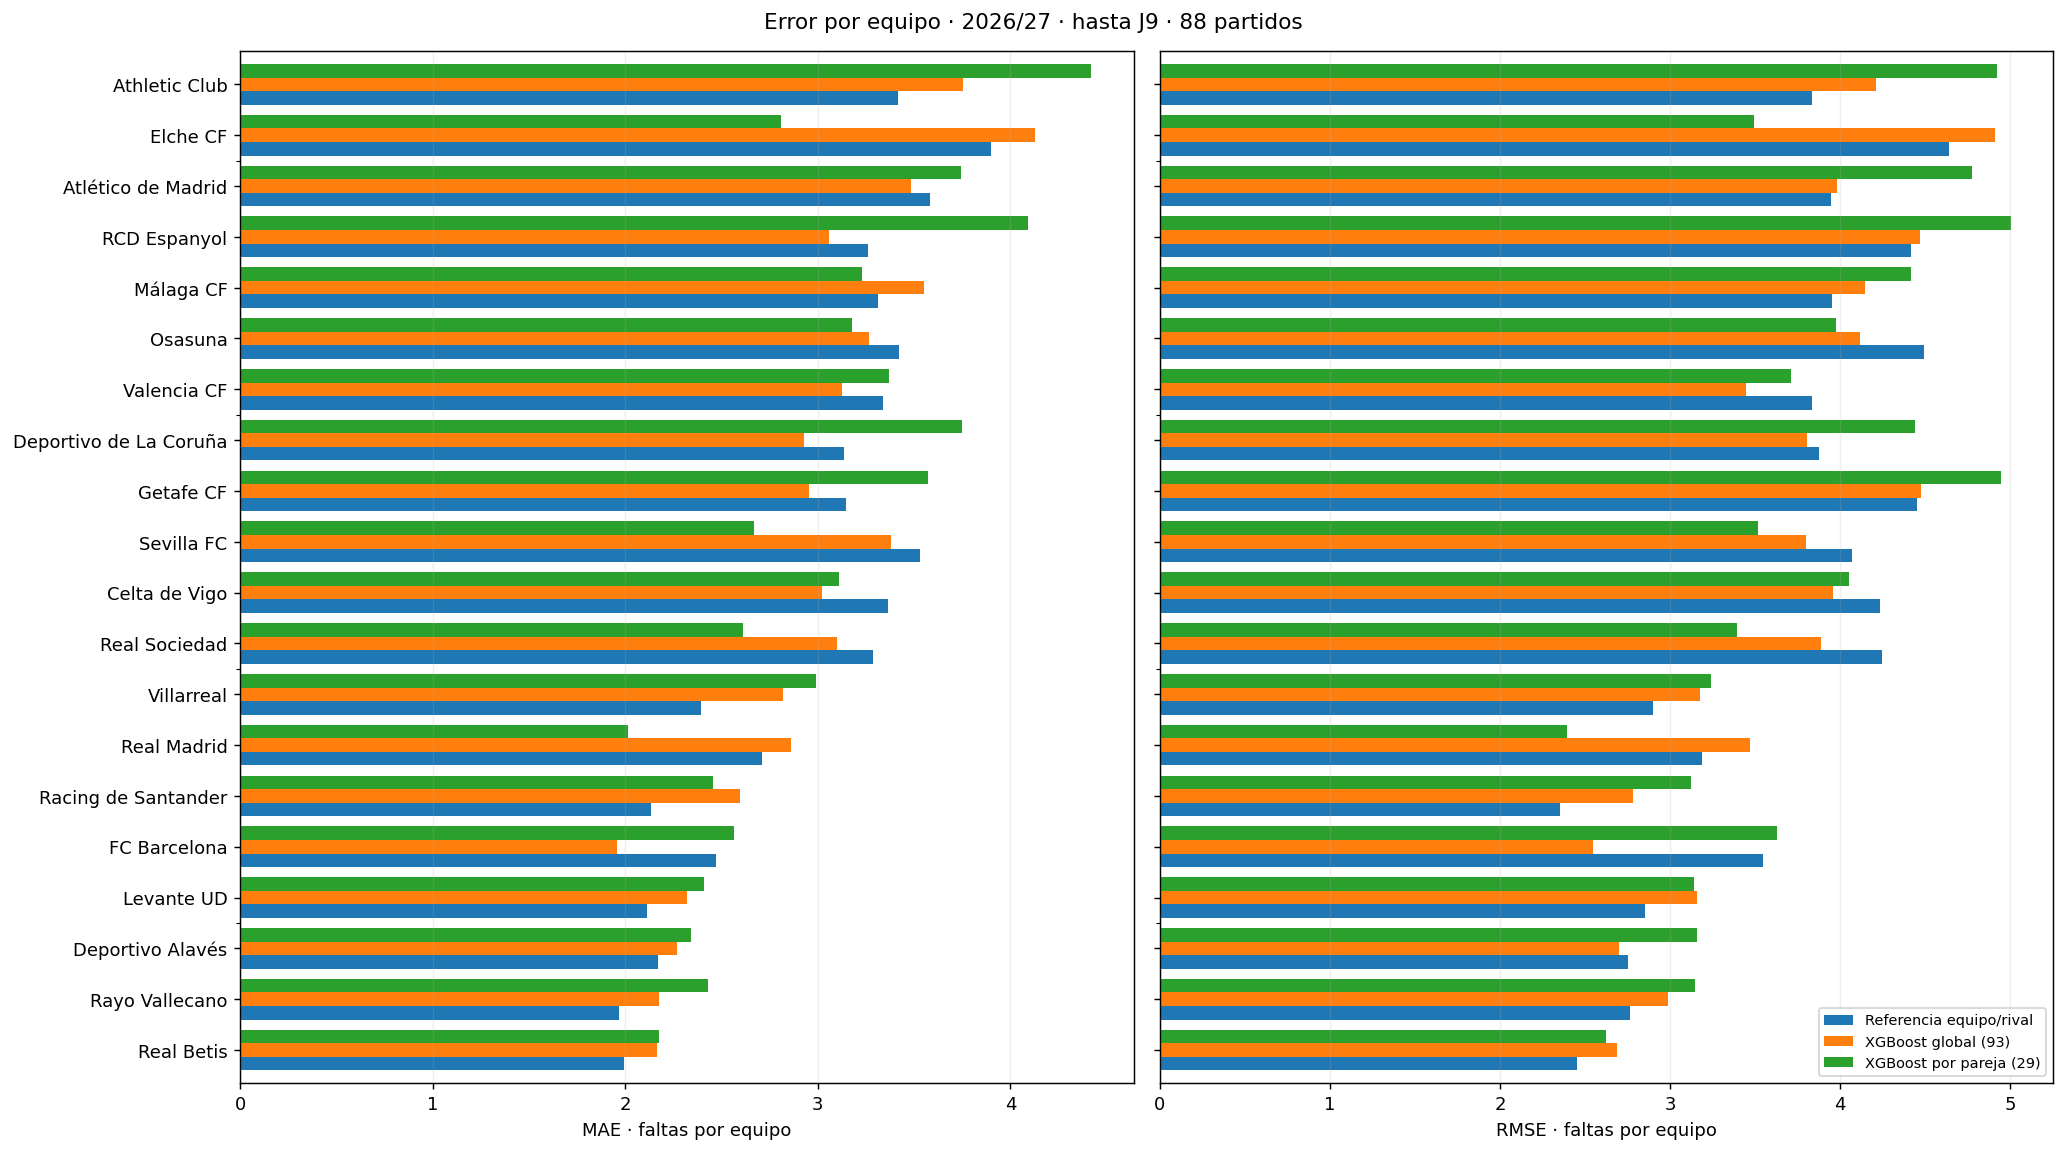

modelo,n,partidos,MAE,RMSE,sesgo,sobreestima_pct,infraestima_pct,exacta_pct,mediana_error,asimetria_error,error_absoluto_p90,muestra
equipo_rival_previo,118,59,3.0118,3.78837,0.360491,54.2373,45.7627,0,0.136306,-0.341835,5.93401,Desarrollo
grid_global93_030,118,59,2.98096,3.71057,0.143913,48.3051,51.6949,0,-0.199422,-0.303694,5.67179,Desarrollo
grid_pareja29_equilibrada_024,118,59,2.93537,3.69529,0.403425,52.5424,47.4576,0,0.220452,-0.211226,5.62637,Desarrollo
equipo_rival_previo,58,29,2.78381,3.56823,0.319053,60.3448,39.6552,0,0.304476,-0.468976,6.29128,Contraste temporal
grid_global93_030,58,29,2.86861,3.66715,0.208812,50,50,0,-0.0247765,-0.198456,6.48373,Contraste temporal
grid_pareja29_equilibrada_024,58,29,3.09081,4.07327,0.294888,55.1724,44.8276,0,0.332825,-0.177074,6.93293,Contraste temporal
equipo_rival_previo,176,88,2.93667,3.71726,0.346835,56.25,43.75,0,0.289085,-0.374988,6.28933,Temporada actual acumulada
grid_global93_030,176,88,2.94393,3.69632,0.1653,48.8636,51.1364,0,-0.167902,-0.26817,5.82796,Temporada actual acumulada
grid_pareja29_equilibrada_024,176,88,2.9866,3.82398,0.367657,53.4091,46.5909,0,0.263307,-0.200404,6.11057,Temporada actual acumulada


modelo,n,partidos,MAE,RMSE,sesgo,sobreestima_pct,infraestima_pct,exacta_pct,mediana_error,asimetria_error,error_absoluto_p90,muestra
equipo_rival_previo,59,59,4.56538,5.62902,0.720982,54.2373,45.7627,0,1.3335,-0.20162,9.92266,Desarrollo
grid_global93_030,59,59,4.4539,5.50365,0.287826,52.5424,47.4576,0,0.203786,-0.201315,9.27878,Desarrollo
grid_pareja29_equilibrada_024,59,59,4.62055,5.63629,0.80685,54.2373,45.7627,0,1.09094,-0.166616,8.63798,Desarrollo
equipo_rival_previo,29,29,4.34252,5.48858,0.638106,65.5172,34.4828,0,0.990779,-0.448606,8.95191,Contraste temporal
grid_global93_030,29,29,4.29148,5.46317,0.417624,51.7241,48.2759,0,0.102302,-0.324687,8.46906,Contraste temporal
grid_pareja29_equilibrada_024,29,29,4.90003,6.09493,0.589776,55.1724,44.8276,0,0.62918,-0.25172,9.08009,Contraste temporal
equipo_rival_previo,88,88,4.49194,5.58313,0.69367,57.9545,42.0455,0,0.995178,-0.272459,9.72962,Temporada actual acumulada
grid_global93_030,88,88,4.40037,5.49034,0.3306,52.2727,47.7273,0,0.153044,-0.236535,9.25588,Temporada actual acumulada
grid_pareja29_equilibrada_024,88,88,4.71265,5.79145,0.735314,54.5455,45.4545,0,0.921603,-0.199966,8.92577,Temporada actual acumulada


modelo,muestra,n,partidos,porcentaje_error_hasta2,porcentaje_error_hasta3,porcentaje_error_desde5,maximo_error_absoluto
grid_global93_030,Desarrollo,118,59,34.7458,53.3898,18.6441,11.4138
equipo_rival_previo,Desarrollo,118,59,43.2203,55.9322,22.0339,10.8689
grid_pareja29_equilibrada_024,Desarrollo,118,59,44.0678,55.9322,19.4915,11.6699
grid_global93_030,Contraste temporal,58,29,41.3793,60.3448,17.2414,9.2601
equipo_rival_previo,Contraste temporal,58,29,43.1034,68.9655,13.7931,8.53352
grid_pareja29_equilibrada_024,Contraste temporal,58,29,44.8276,56.8966,25.8621,9.55102
grid_global93_030,Temporada actual acumulada,176,88,36.9318,55.6818,18.1818,11.4138
equipo_rival_previo,Temporada actual acumulada,176,88,43.1818,60.2273,19.3182,10.8689
grid_pareja29_equilibrada_024,Temporada actual acumulada,176,88,44.3182,56.25,21.5909,11.6699


In [4]:
mostrar("Error por equipo, método y muestra",diag_actual["metricas_por_equipo"],abierto=True)
figura_actual("error_por_equipo.png")
mostrar("Errores generales",diag_actual["metricas"])
mostrar("Errores del total del partido",diag_actual["metricas_totales"])
mostrar("Errores pequeños y grandes, sin eliminar casos",diag_actual["precision"])

**Lectura de J9.** En el global, el MAE observado va de 1,96 en FC Barcelona a 4,13 en Elche CF. La muestra por club es de siete a nueve encuentros: la heterogeneidad merece seguimiento, sin convertir este ranking pequeño en una regla futura.

**Precisión práctica.** El global queda a dos faltas o menos en el 36,9 % de las predicciones y falla por cinco o más en el 18,2 %. La referencia alcanza el 43,2 % y 19,3 %, respectivamente. La pareja llega más veces a errores pequeños (44,3 %), pero acumula más errores de cinco o más (21,6 %); por eso no lidera el RMSE.

<a id="variabilidad"></a>
## 4. Variabilidad real y error del modelo

Desviación estándar, rango e intervalo intercuartílico describen cuánto varían las faltas reales.
Son conceptos distintos del MAE y RMSE del predictor. Los resultados se cuentan una sola vez,
independientemente de cuántos modelos se comparen. Una desviación con un único caso no se estima.

id_equipo,equipo,n_partidos,media_faltas,desv_faltas,minimo,maximo,iqr,muestra
LL-T-11,Levante UD,5,10,2,7,12,2,Desarrollo
LL-T-12,Málaga CF,6,12.3333,3.07679,9,17,4,Desarrollo
LL-T-13,Osasuna,6,12.8333,3.18852,9,17,4.75,Desarrollo
LL-T-14,Rayo Vallecano,6,13.5,2.88097,10,18,3.25,Desarrollo
LL-T-15,Real Madrid,6,8.83333,2.48328,6,13,2.5,Desarrollo
LL-T-16,Real Sociedad,6,12.5,4.23084,8,19,5.5,Desarrollo
LL-T-17,Sevilla FC,6,15.1667,4.21505,8,20,3.75,Desarrollo
LL-T-18,Valencia CF,6,10.8333,4.44597,5,17,5.75,Desarrollo
LL-T-2,Atlético de Madrid,6,11.3333,4.4572,6,17,6.75,Desarrollo
LL-T-20,Villarreal,6,11,3.09839,7,14,5.25,Desarrollo


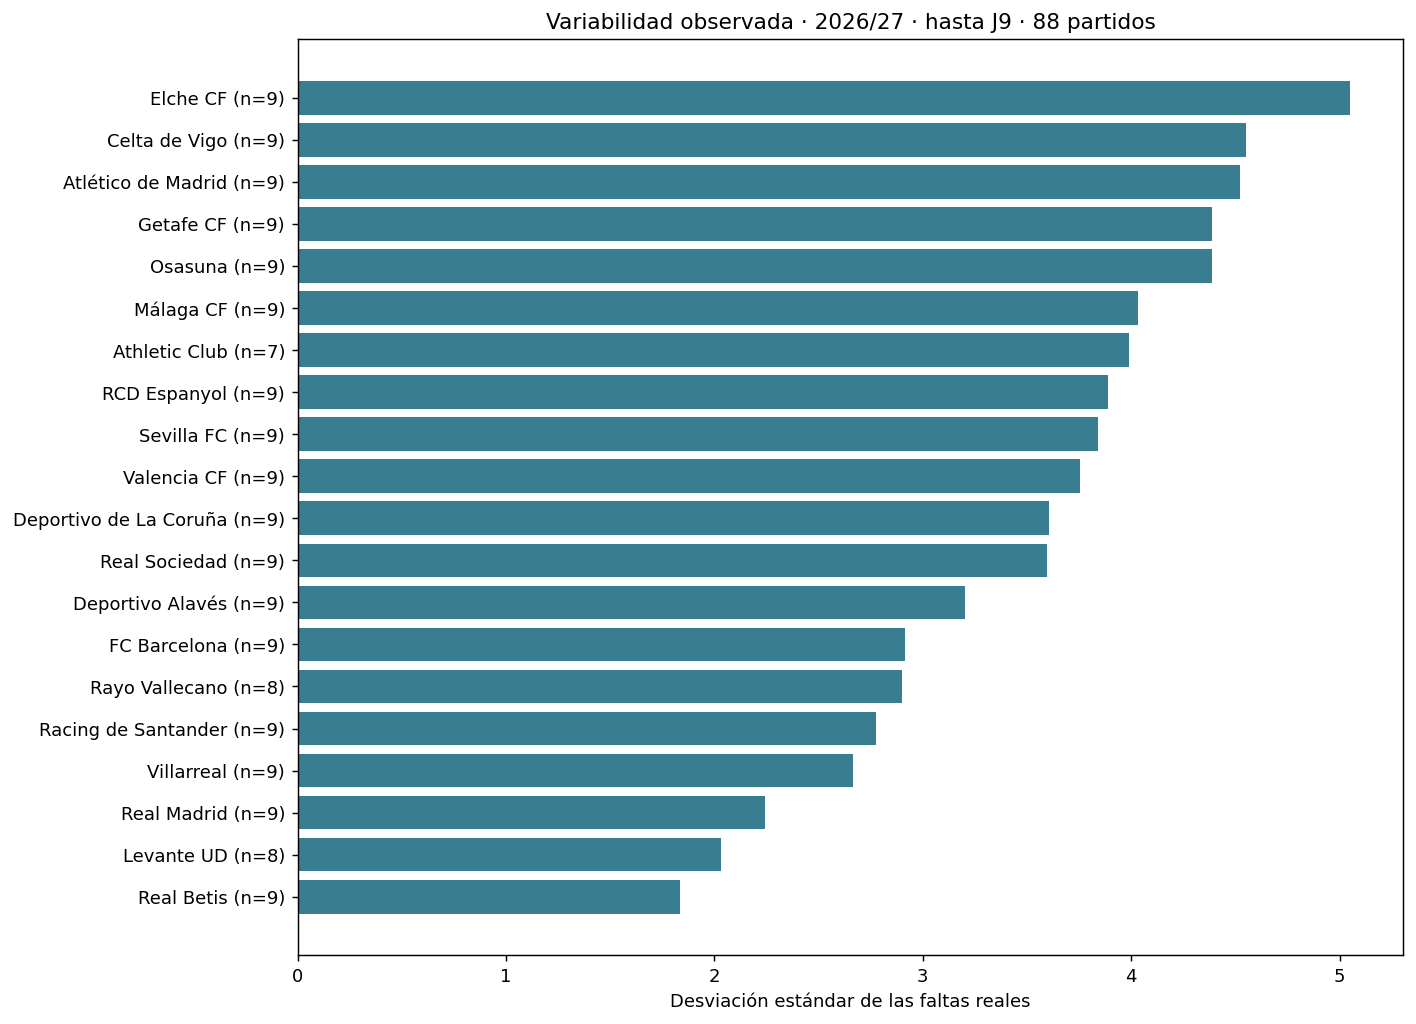

In [5]:
mostrar("Variación de las faltas reales",diag_actual["variabilidad_observada"])
figura_actual("variabilidad_observada.png")

<a id="sesgo"></a>
## 5. ¿Nos pasamos o nos quedamos cortos?

El error con signo es predicción menos resultado: positivo indica sobreestimación y negativo,
infraestimación. Miramos frecuencia y magnitud por club y muestra. Una media cercana a cero
puede ocultar fallos grandes en ambos sentidos y no demuestra simetría. MAE no es una sigma
ni una banda de probabilidad para el siguiente partido.

muestra,modelo,n_salidas,n_partidos,MAE,RMSE,sesgo,mediana_error,n_sobre,n_debajo,n_exactas,porcentaje_sobre,porcentaje_debajo,exceso_medio,defecto_medio,p05,p25,p75,p95,asimetria_fisher
Desarrollo,grid_global93_030,118,59,2.98096,3.71057,0.143913,-0.199422,57,61,0,48.3051,51.6949,3.23451,2.74403,-5.34638,-2.45524,3.18415,5.76557,-0.303694
Desarrollo,equipo_rival_previo,118,59,3.0118,3.78837,0.360491,0.136306,64,54,0,54.2373,45.7627,3.10883,2.8968,-5.37547,-1.86971,2.96859,6.3349,-0.341835
Desarrollo,grid_pareja29_equilibrada_024,118,59,2.93537,3.69529,0.403425,0.220452,62,56,0,52.5424,47.4576,3.17724,2.66759,-4.96406,-2.04654,2.74005,6.00997,-0.211226
Contraste temporal,grid_global93_030,58,29,2.86861,3.66715,0.208812,-0.0247765,29,29,0,50,50,3.07742,2.6598,-6.70068,-1.54339,2.51781,6.15118,-0.198456
Contraste temporal,equipo_rival_previo,58,29,2.78381,3.56823,0.319053,0.304476,35,23,0,60.3448,39.6552,2.57094,3.10773,-6.50066,-1.57764,2.82854,5.04764,-0.468976
Contraste temporal,grid_pareja29_equilibrada_024,58,29,3.09081,4.07327,0.294888,0.332825,32,26,0,55.1724,44.8276,3.06829,3.11853,-6.85557,-2.08132,2.94651,6.80351,-0.177074
Temporada actual acumulada,grid_global93_030,176,88,2.94393,3.69632,0.1653,-0.167902,86,90,0,48.8636,51.1364,3.18154,2.71689,-5.69588,-2.4201,3.0128,5.82235,-0.26817
Temporada actual acumulada,equipo_rival_previo,176,88,2.93667,3.71726,0.346835,0.289085,99,77,0,56.25,43.75,2.91867,2.95981,-5.92746,-1.8268,2.88601,6.27568,-0.374988
Temporada actual acumulada,grid_pareja29_equilibrada_024,176,88,2.9866,3.82398,0.367657,0.263307,94,82,0,53.4091,46.5909,3.14015,2.81057,-5.28004,-2.08138,2.78151,6.31704,-0.200404


muestra,modelo,id_equipo,equipo,n_salidas,n_partidos,MAE,RMSE,sesgo,mediana_error,n_sobre,n_debajo,n_exactas,porcentaje_sobre,porcentaje_debajo,exceso_medio,defecto_medio,p05,p25,p75,p95,asimetria_fisher
Desarrollo,grid_global93_030,LL-T-21,Deportivo Alavés,6,6,2.44705,2.95609,0.229105,-0.893177,2,4,0,33.3333,66.6667,4.01424,1.66346,-2.69618,-1.7016,1.51989,4.89033,1.18534
Desarrollo,grid_global93_030,LL-T-9,Getafe CF,6,6,3.43649,5.29377,-0.463359,-0.188976,3,3,0,50,50,2.97313,3.89985,-8.00954,-0.674042,0.95376,5.95842,-0.740133
Desarrollo,equipo_rival_previo,LL-T-21,Deportivo Alavés,6,6,2.30421,2.98434,0.386569,-1.13647,2,4,0,33.3333,66.6667,4.03617,1.43823,-1.8055,-1.53143,0.936444,5.2676,1.79033
Desarrollo,equipo_rival_previo,LL-T-9,Getafe CF,6,6,3.56317,5.18853,-0.922929,-0.448605,3,3,0,50,50,2.64024,4.4861,-8.45078,-1.39552,1.04086,5.05741,-0.971794
Desarrollo,grid_pareja29_equilibrada_024,LL-T-21,Deportivo Alavés,6,6,2.43275,3.48025,0.535587,-0.599522,2,4,0,33.3333,66.6667,4.4525,1.42287,-2.81977,-1.02466,0.898025,6.01377,1.57767
Desarrollo,grid_pareja29_equilibrada_024,LL-T-9,Getafe CF,6,6,4.5528,5.75306,0.662843,2.52871,5,1,0,83.3333,16.6667,3.12939,11.6699,-8.56111,1.15111,3.93706,5.20164,-2.07905
Desarrollo,grid_global93_030,LL-T-17,Sevilla FC,6,6,3.87686,4.29182,-1.97478,-3.36259,2,4,0,33.3333,66.6667,2.85311,4.38873,-5.46379,-4.90486,-0.519959,4.11683,1.32968
Desarrollo,grid_global93_030,LL-T-14,Rayo Vallecano,6,6,1.91464,2.49419,0.055027,0.0488114,3,3,0,50,50,1.96967,1.85961,-3.5369,-0.531697,1.43802,3.12336,-0.708072
Desarrollo,equipo_rival_previo,LL-T-17,Sevilla FC,6,6,4.13042,4.58708,-1.98975,-3.16629,2,4,0,33.3333,66.6667,3.21099,4.59013,-6.43344,-4.67793,-0.202447,4.42713,1.01936
Desarrollo,equipo_rival_previo,LL-T-14,Rayo Vallecano,6,6,1.8289,2.6129,-0.0535559,0.330983,4,2,0,66.6667,33.3333,1.33151,2.82368,-4.09794,-0.199204,1.44842,2.63798,-1.50578


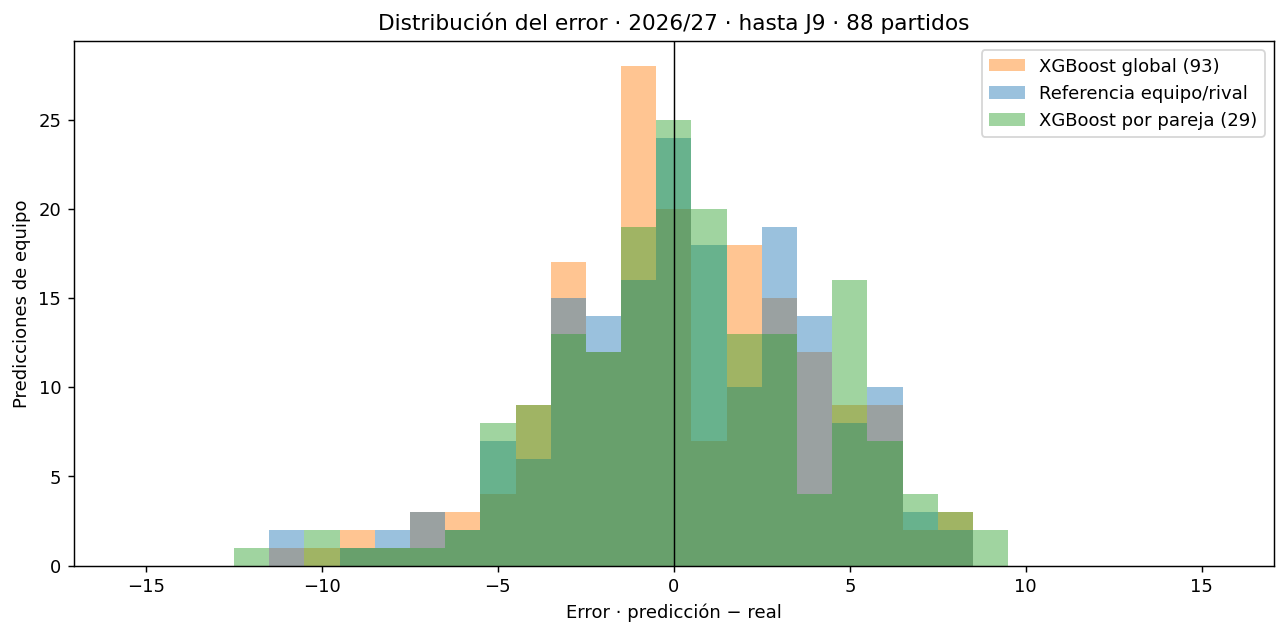

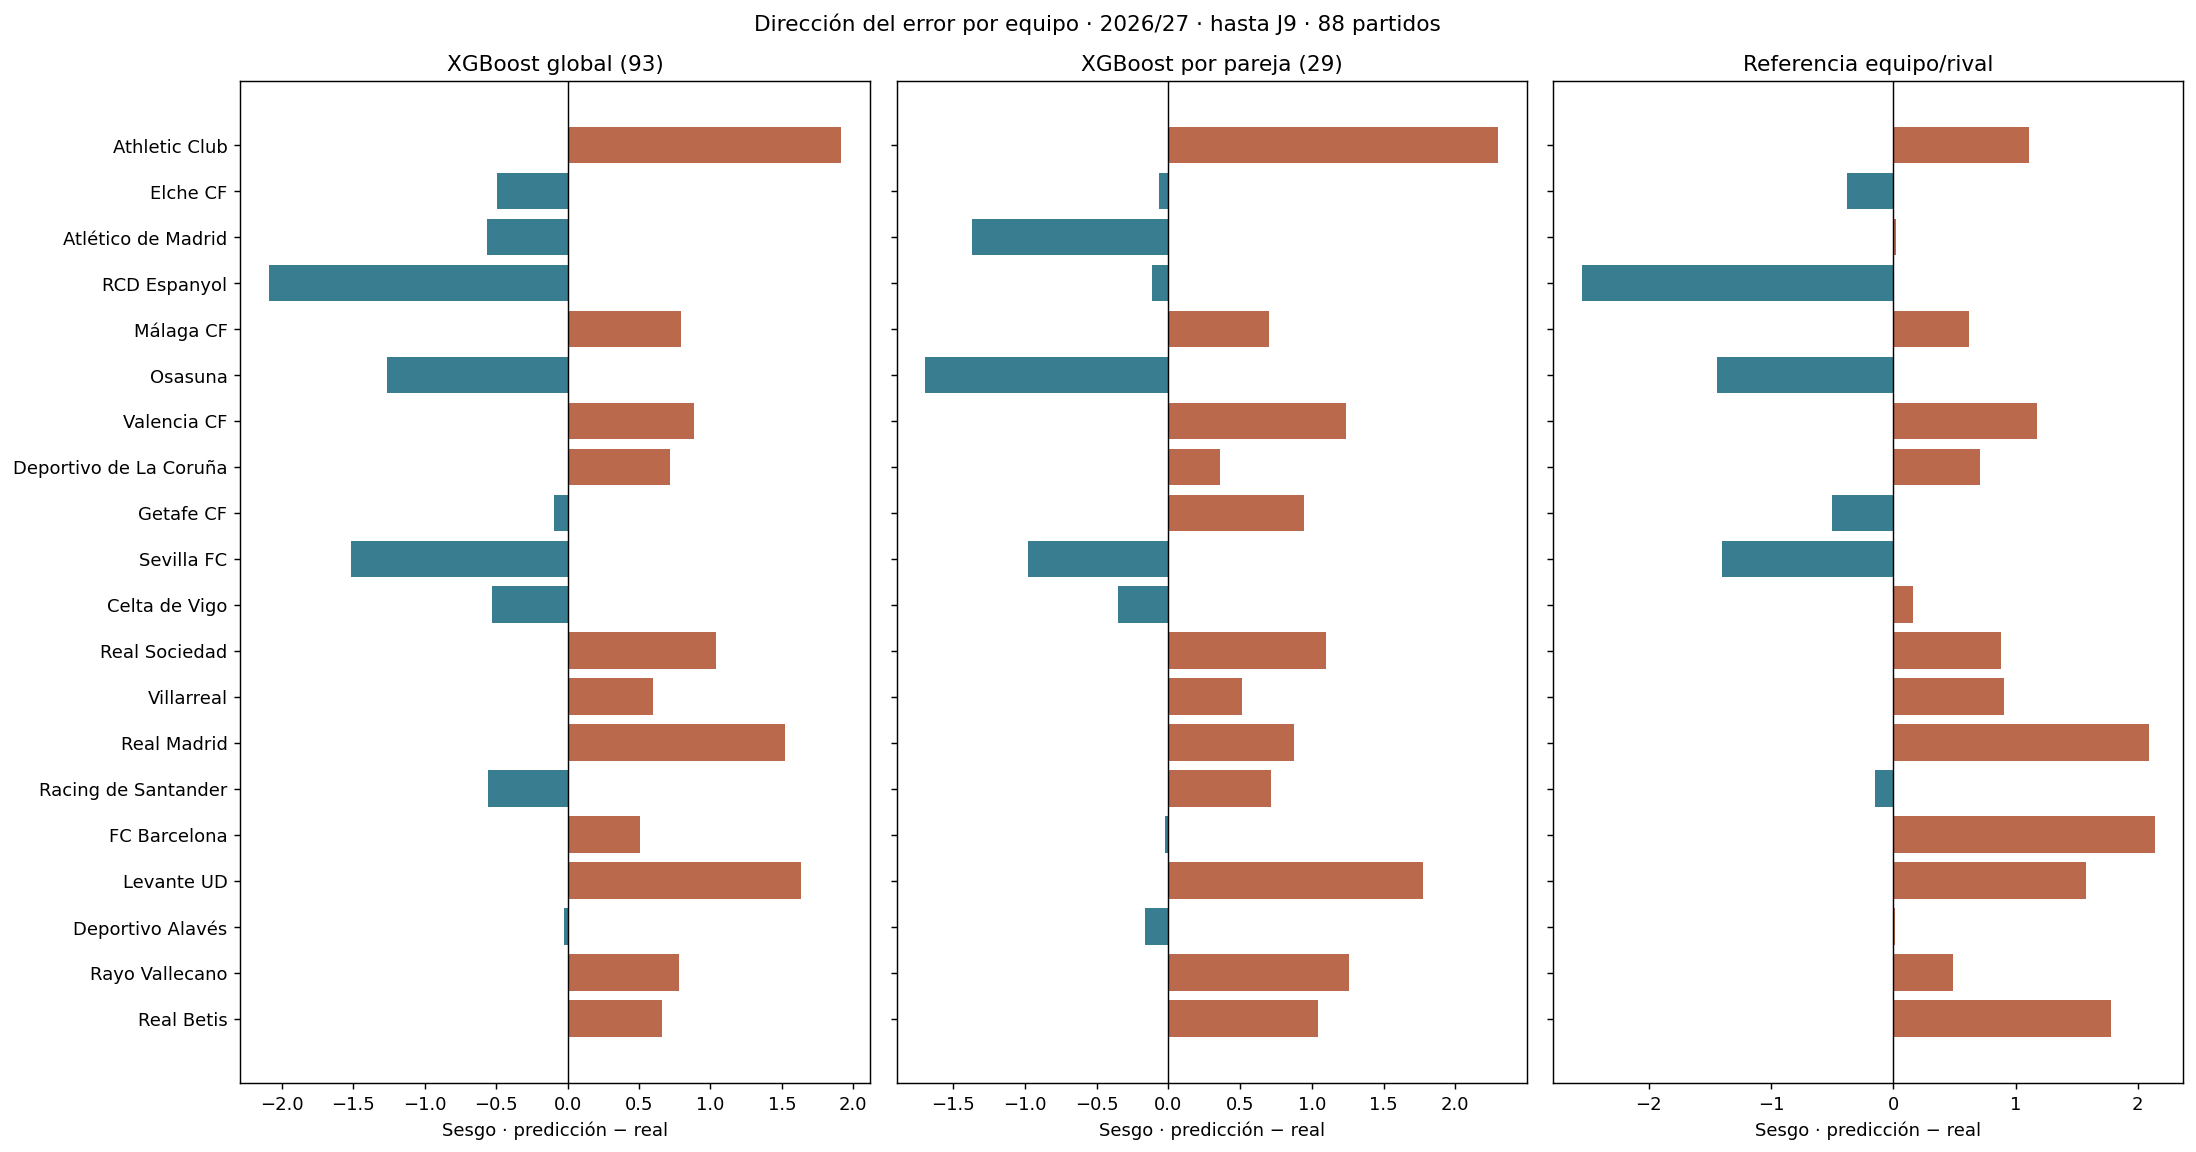

In [6]:
mostrar("Dirección y magnitud del error",diag_actual["sesgos_generales"])
mostrar("Sesgo por club y método",diag_actual["sesgos_por_equipo"])
figura_actual("distribucion_errores.png")
figura_actual("sesgo_por_equipo.png")

**Lectura de J9.** El sesgo medio es positivo en los tres métodos: global +0,17, referencia +0,35 y pareja +0,37 faltas. El global sobreestima el 48,9 % de las veces y subestima el 51,1 %: su media positiva procede de la magnitud de los errores, no de sobreestimar más veces.

<a id="contextos"></a>
## 6. Contexto y localía

Comparamos errores por condición de local o visitante y por grupos previos de equipos.
Los grupos se reconstruyen antes de cada consulta; si falta perfil se conserva esa ausencia.
Son análisis descriptivos con muestras pequeñas, sin escoger retrospectivamente un ganador
distinto para cada tipo de encuentro.

muestra,desglose,modelo,tipo_partido,n_salidas,n_partidos,MAE,RMSE,sesgo,mediana_error,n_sobre,n_debajo,n_exactas,porcentaje_sobre,porcentaje_debajo,exceso_medio,defecto_medio,p05,p25,p75,p95,asimetria_fisher,cruce_equipo_rival,localia,MAE_referencia,RMSE_referencia,diferencia_MAE_referencia,diferencia_RMSE_referencia
Desarrollo,Partido,grid_global93_030,Sin perfil suficiente,60,30,3.06912,3.58632,0.219584,-0.113124,30,30,0,50,50,3.28871,2.84954,-5.32681,-2.91189,3.23452,5.60126,0.0867537,Sin datos,Sin datos,3.14871,3.78524,-0.0795872,-0.19892
Desarrollo,Partido,equipo_rival_previo,Sin perfil suficiente,60,30,3.14871,3.78524,0.128228,-0.199875,29,31,0,48.3333,51.6667,3.38994,2.92305,-5.37328,-2.75518,2.74533,6.45617,0.143958,Sin datos,Sin datos,3.14871,3.78524,0,0
Desarrollo,Partido,grid_pareja29_equilibrada_024,Sin perfil suficiente,60,30,2.896,3.50095,0.244409,-0.201171,29,31,0,48.3333,51.6667,3.2487,2.56605,-4.9347,-2.17057,2.6553,5.96808,0.32818,Sin datos,Sin datos,3.14871,3.78524,-0.252712,-0.284286
Desarrollo,Partido,grid_global93_030,Grupo 2 — Grupo 2,40,20,3.00228,3.95963,0.175017,-0.00832653,20,20,0,50,50,3.17729,2.82726,-5.21858,-2.2407,3.23531,5.76547,-0.768561,Sin datos,Sin datos,3.04374,3.97496,-0.0414637,-0.0153275
Desarrollo,Partido,equipo_rival_previo,Grupo 2 — Grupo 2,40,20,3.04374,3.97496,0.499529,0.553627,23,17,0,57.5,42.5,3.0811,2.99319,-5.32679,-1.67557,3.15323,6.32273,-0.913509,Sin datos,Sin datos,3.04374,3.97496,0,0
Desarrollo,Partido,grid_pareja29_equilibrada_024,Grupo 2 — Grupo 2,40,20,3.21155,4.14149,0.617107,1.28192,26,14,0,65,35,2.94512,3.70635,-6.67043,-1.38856,3.22521,5.69414,-0.946204,Sin datos,Sin datos,3.04374,3.97496,0.167812,0.166533
Desarrollo,Partido,grid_global93_030,Grupo 1 — Grupo 1,4,2,2.18421,2.79261,-2.18421,-1.66688,0,4,0,0,100,Sin datos,2.18421,-4.56819,-2.93465,-0.916445,-0.524479,-1.2324,Sin datos,Sin datos,1.14636,1.46362,1.03785,1.32898
Desarrollo,Partido,equipo_rival_previo,Grupo 1 — Grupo 1,4,2,1.14636,1.46362,-0.643382,-0.437493,2,2,0,50,50,0.502976,1.78974,-2.36064,-1.38195,0.301078,0.785633,-0.65821,Sin datos,Sin datos,1.14636,1.46362,0,0
Desarrollo,Partido,grid_pareja29_equilibrada_024,Grupo 1 — Grupo 1,4,2,0.884353,1.26298,-0.884353,-0.543897,0,4,0,0,100,Sin datos,0.884353,-2.14055,-1.11663,-0.311619,-0.104794,-1.63073,Sin datos,Sin datos,1.14636,1.46362,-0.262005,-0.200636
Desarrollo,Partido,grid_global93_030,Grupo 1 — Grupo 2,14,7,2.76983,3.72845,0.395918,0.00978184,7,7,0,50,50,3.16575,2.37391,-5.72586,-0.775514,3.19163,5.69644,-0.683731,Sin datos,Sin datos,2.86678,3.71523,-0.0969515,0.0132231


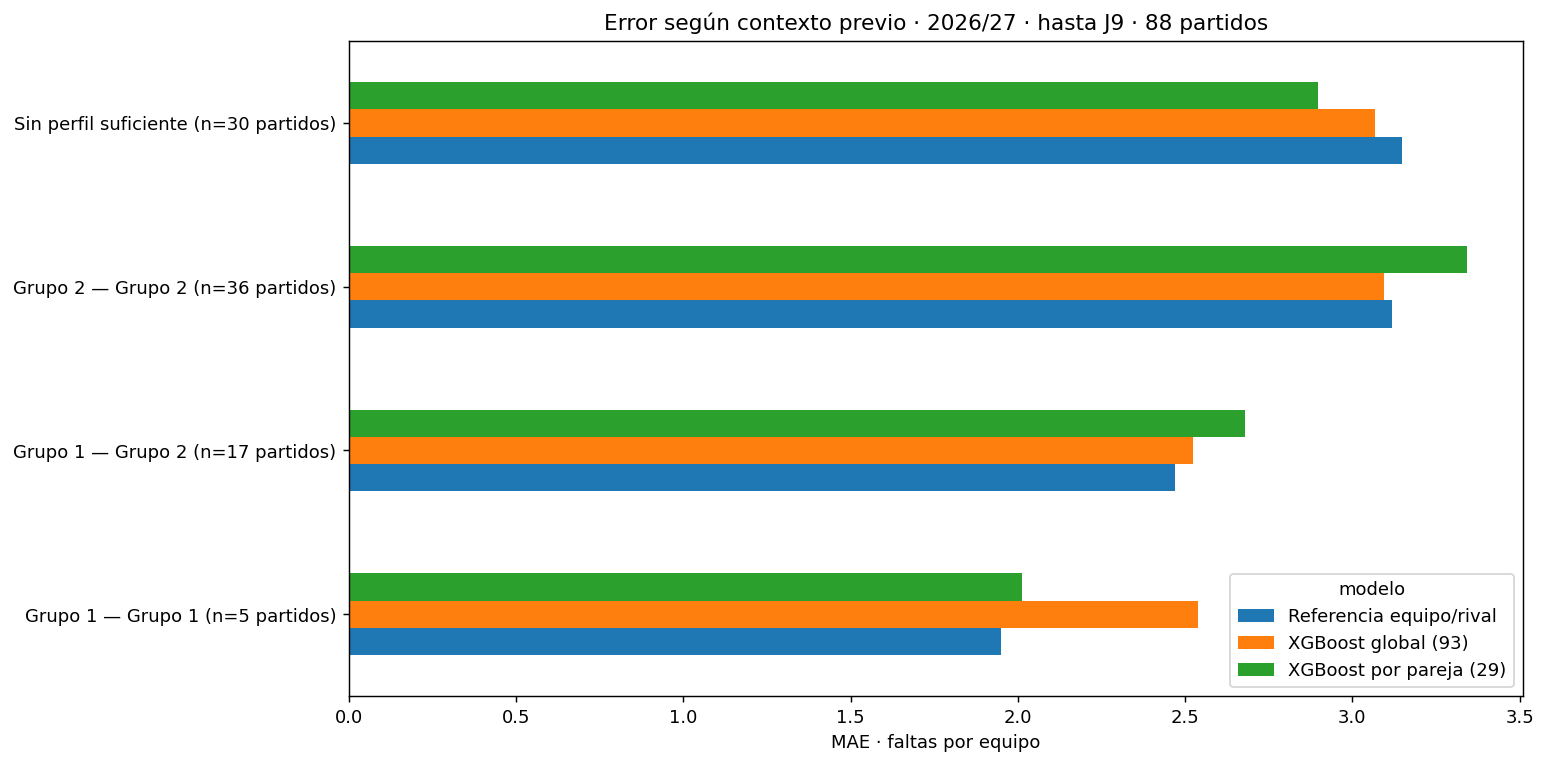

In [7]:
mostrar("Contextos previos y localía",diag_actual["contextos"])
figura_actual("error_por_contexto.png")

<a id="discriminacion"></a>
## 7. ¿Las previsiones altas anticipan más faltas?

Dos límites calculados con las previsiones del desarrollo definen tres tramos comunes.
Se aplican sin reajustar al contraste. Miramos si las faltas reales aumentan con el tramo previsto
y si predicción y resultado se ordenan de manera parecida. Dispersar más las predicciones
no basta: también deben acertar mejor.

limite_bajo,limite_alto
11.967,13.4044


muestra,modelo,tramo,prediccion_media,observado_medio,prediccion_minima,prediccion_maxima,n_salidas,n_partidos,MAE,RMSE,sesgo,mediana_error,n_sobre,n_debajo,n_exactas,porcentaje_sobre,porcentaje_debajo,exceso_medio,defecto_medio,p05,p25,p75,p95,asimetria_fisher
Desarrollo,grid_global93_030,Bajas,10.5485,10.1842,8.02343,11.9185,38,31,2.44764,2.95193,0.364287,0.0332799,19,19,0,50,50,2.81192,2.08335,-4.14393,-2.09536,2.38926,5.30299,0.19318
Desarrollo,grid_global93_030,Intermedias,12.5923,12.9167,11.9694,13.3806,36,30,3.48288,4.3904,-0.324373,-0.48406,16,20,0,44.4444,55.5556,3.55332,3.42653,-7.06537,-3.33523,3.51653,5.81874,-0.333442
Desarrollo,grid_global93_030,Altas,14.1776,13.8409,13.4384,15.7501,44,34,3.03089,3.69154,0.336733,-0.0554833,22,22,0,50,50,3.36762,2.69415,-4.38927,-2.80961,3.45774,5.73784,-0.285443
Desarrollo,equipo_rival_previo,Bajas,11.3602,10.2059,9.82603,11.9623,34,28,2.76251,3.49548,1.15433,1.07689,22,12,0,64.7059,35.2941,3.02665,2.27826,-4.13258,-0.418493,3.67403,5.73663,-0.389717
Desarrollo,equipo_rival_previo,Intermedias,12.7499,13,12.0257,13.3896,52,38,3.18365,3.9889,-0.250088,-0.211078,26,26,0,50,50,2.93357,3.43374,-6.03851,-3.06559,2.83368,5.51755,-0.468297
Desarrollo,equipo_rival_previo,Altas,14.1967,13.6875,13.499,17,32,25,2.99741,3.75288,0.509228,-0.0985306,16,16,0,50,50,3.50664,2.48818,-4.82404,-1.95238,3.25475,6.46565,0.150708
Desarrollo,grid_pareja29_equilibrada_024,Bajas,10.6253,10.9783,6.15511,11.9617,46,33,2.34936,2.89905,-0.352958,-0.444364,20,26,0,43.4783,56.5217,2.29586,2.39051,-5.21843,-2.16158,1.73707,4.28383,-0.0717817
Desarrollo,grid_pareja29_equilibrada_024,Intermedias,12.691,11.8,11.9916,13.3077,30,26,3.36878,4.32041,0.890989,0.674239,18,12,0,60,40,3.54981,3.09724,-4.31223,-1.56024,4.55775,6.51417,-0.586611
Desarrollo,grid_pareja29_equilibrada_024,Altas,15.2169,14.3333,13.4342,20.0997,42,29,3.26762,3.97829,0.883584,1.04758,24,18,0,57.1429,42.8571,3.6323,2.78138,-4.4234,-1.97973,4.37857,7.07161,-0.296135
Contraste temporal,grid_global93_030,Bajas,10.6466,11.5789,9.39016,11.9621,19,16,2.23491,3.22458,-0.932396,-0.813058,7,12,0,36.8421,63.1579,1.7677,2.50745,-7.58425,-1.3459,1.35397,2.46066,-1.33434


muestra,modelo,n_salidas,media_predicha,media_real,desv_predicciones,desv_observada,razon_dispersion,correlacion_pearson,correlacion_spearman
Desarrollo,grid_global93_030,118,12.5253,12.3814,1.65581,3.98699,0.415304,0.361472,0.386245
Desarrollo,equipo_rival_previo,118,12.7418,12.3814,1.19228,3.98699,0.299043,0.312843,0.355631
Desarrollo,grid_pareja29_equilibrada_024,118,12.7848,12.3814,2.32634,3.98699,0.583483,0.4151,0.424334
Contraste temporal,grid_global93_030,58,12.4157,12.2069,1.48468,3.81023,0.389658,0.272458,0.269257
Contraste temporal,equipo_rival_previo,58,12.5259,12.2069,0.893417,3.81023,0.234478,0.361917,0.320486
Contraste temporal,grid_pareja29_equilibrada_024,58,12.5018,12.2069,2.40847,3.81023,0.632107,0.192032,0.190016
Temporada actual acumulada,grid_global93_030,176,12.4892,12.3239,1.59802,3.91958,0.407702,0.335544,0.349208
Temporada actual acumulada,equipo_rival_previo,176,12.6707,12.3239,1.10487,3.91958,0.281885,0.324182,0.353186
Temporada actual acumulada,grid_pareja29_equilibrada_024,176,12.6915,12.3239,2.35061,3.91958,0.599711,0.342871,0.343929


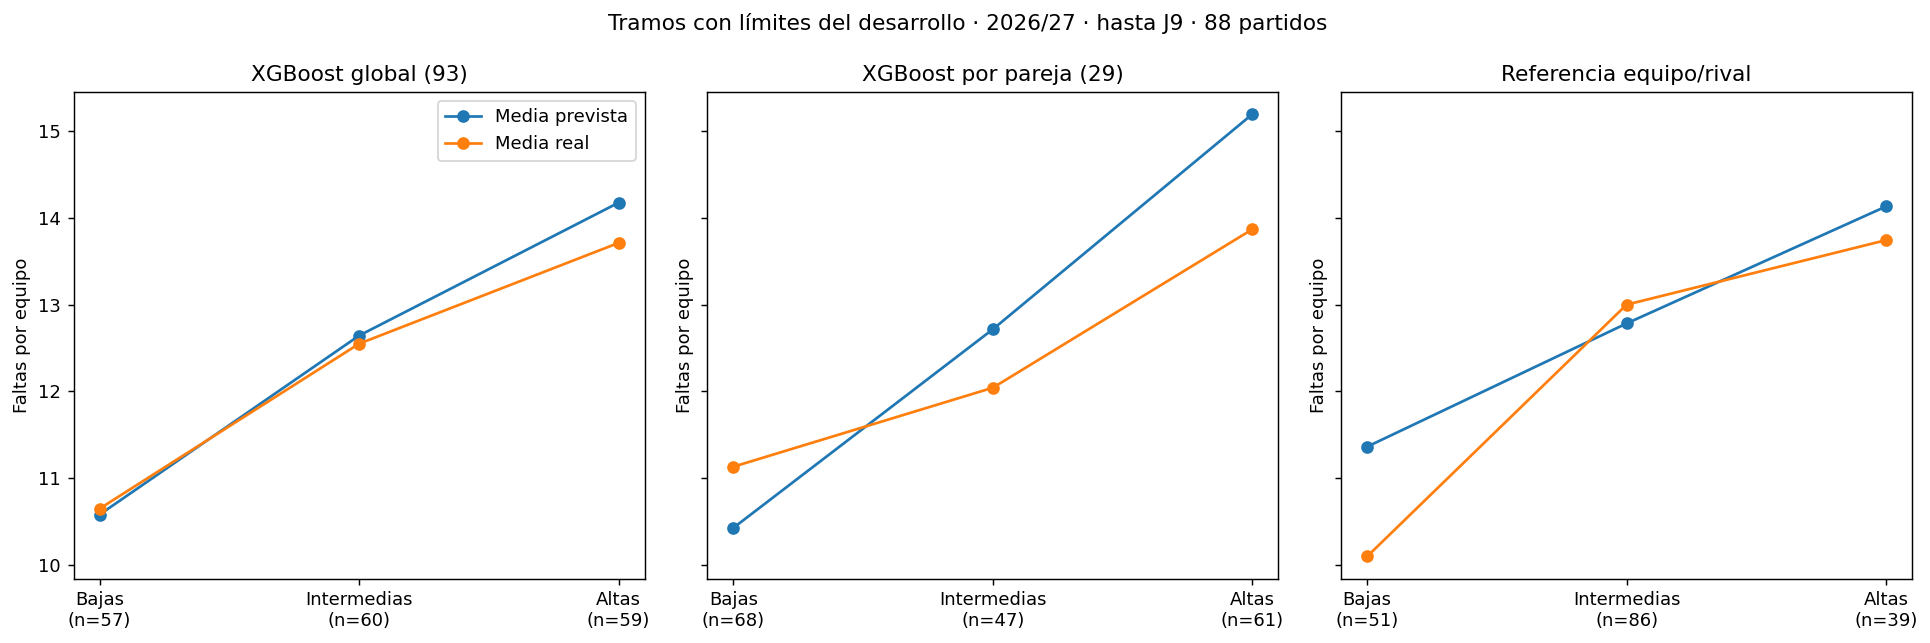

In [8]:
mostrar("Límites calculados únicamente en desarrollo",pd.DataFrame([dict(limite_bajo=diag_actual["limites_tramos"][0],limite_alto=diag_actual["limites_tramos"][1])]))
mostrar("Tramos previstos y medias reales",diag_actual["tramos_prediccion"])
mostrar("Dispersión y correlaciones",diag_actual["dispersion_predicciones"])
figura_actual("discriminacion_y_calibracion.png")

**Lectura de J9.** Las medias reales aumentan de los tramos bajos a los altos en los tres métodos, también en el contraste temporal: hay señal de ordenación. La correlación acumulada de Pearson sigue siendo moderada, entre 0,32 y 0,34. La pareja prevé 15,15 faltas de media en el tramo alto del contraste, frente a 12,84 reales: mayor dispersión no significa mejor calibración.

<a id="casos"></a>
## 8. Qué variables influyeron en tres partidos reales

Elegimos después de evaluar un acierto compartido, un error grande y un desacuerdo entre métodos.
TreeSHAP descompone ambas previsiones XGBoost en contribuciones respecto a una base.
La escala es logarítmica por la pérdida Poisson: las barras no se suman directamente como faltas.
Se comprueba que reconstruyen la predicción; estos ejemplos no demuestran causalidad.

El código de estos tres casos se conserva; sus tablas y gráficos individuales no se distribuyen. Se regeneran localmente al ejecutar con datos reales.


In [9]:
mostrar("Tres casos ilustrativos",exp_actual["casos"],abierto=True)
mostrar("Contribuciones de ambos XGBoost",exp_actual["contribuciones"])
mostrar("Comprobación de aditividad",exp_actual["aditividad"])
mostrar("Soporte, ESS y afinidad",exp_actual["soporte_casos"])
mostrar("Corte y entrenamiento de las reconstrucciones",exp_actual["control_casos"])
mostrar("Fichas previas de los casos",exp_actual["fichas_previas_casos"])
for nombre in entrega["figuras"]:
    if nombre.startswith("caso_"):figura_actual(nombre)

<a id="importancia-casos"></a>
### Resumen de contribuciones en esos ejemplos

Ordenamos para cada XGBoost la media de la contribución absoluta en los tres casos.
Permite localizar qué entradas movieron más esas previsiones. No mide reducción del error
ni equivale a una importancia global fuera de muestra: los ejemplos se eligieron después
de observar sus resultados.

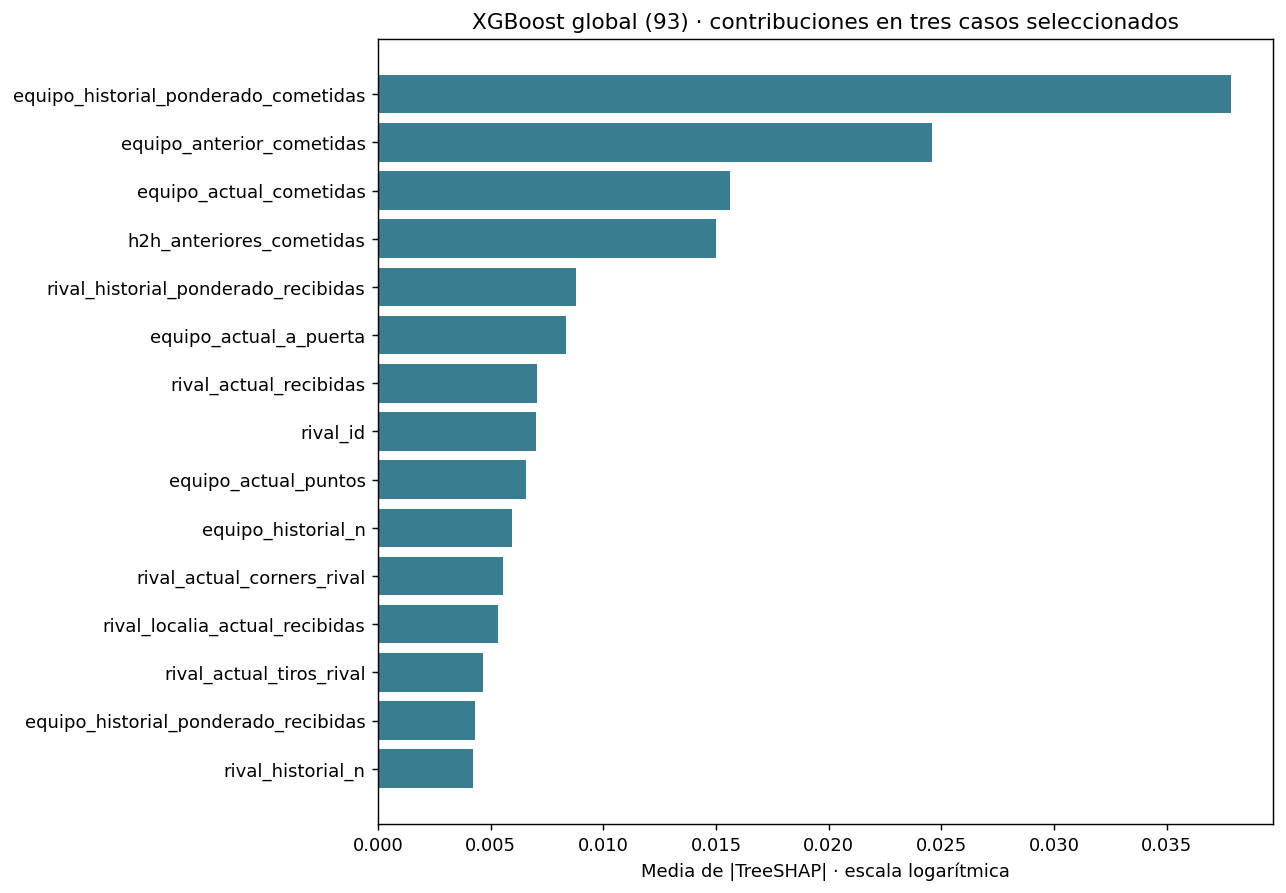

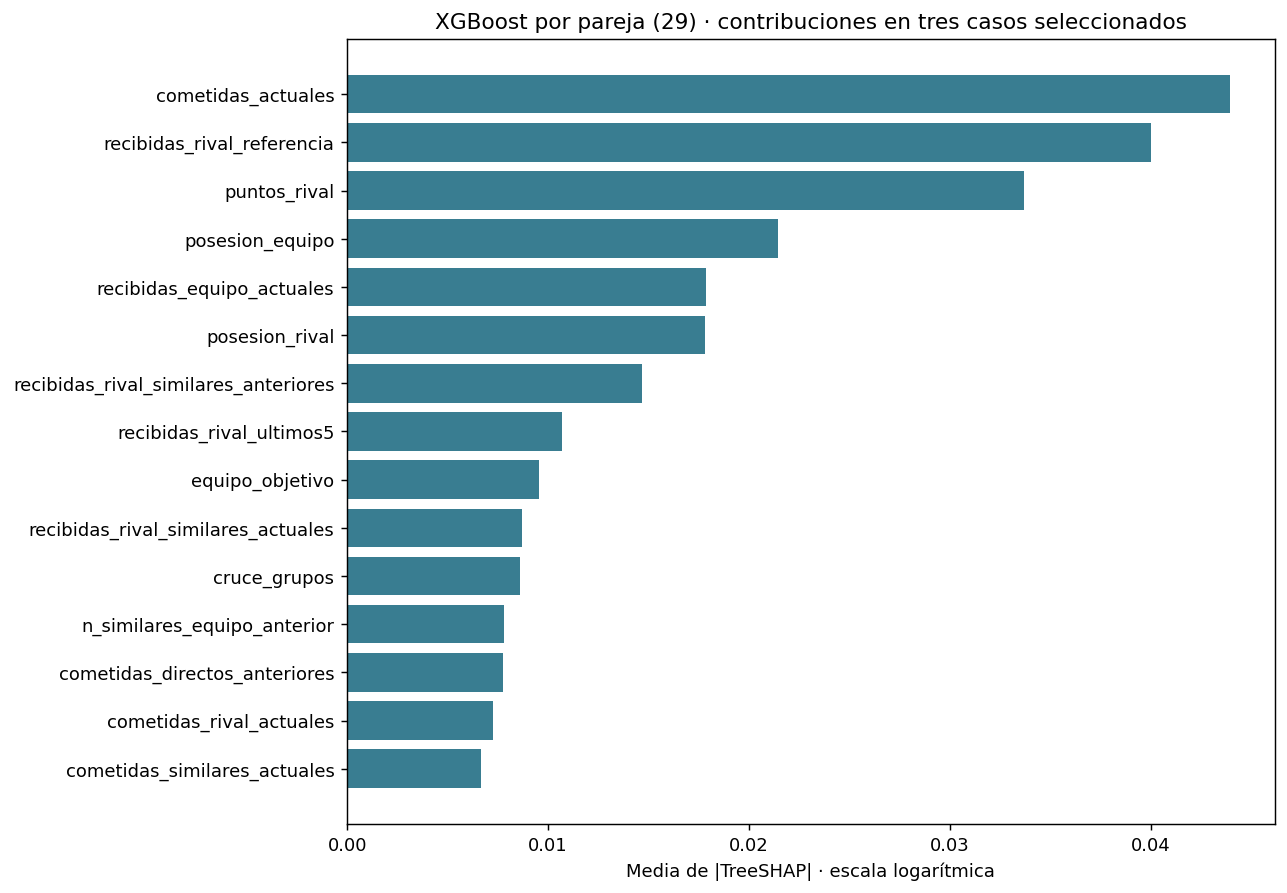

In [10]:
for nombre in entrega["figuras"]:
    if nombre.startswith("contribuciones_resumen_"):figura_actual(nombre)

<a id="diagnosticos-ejecutables"></a>
## 9. Comprobar cobertura y disponibilidad

La evaluación utiliza las recetas finales y 35/35/20/10. Cada encuentro queda fuera de su
entrenamiento y las fichas respetan su propio corte. Se controla la cobertura compartida y
la ausencia de duplicados. Si cambian los CSV, las métricas se recalculan; la búsqueda de
configuraciones no se repite automáticamente.

In [11]:
print("Partidos evaluados:",pred_actuales.id_partido.nunique())
print("Predicciones:",len(pred_actuales),"= dos equipos × tres métodos × partidos")
for campo in ["max_inicio_utilizado_utc","max_disponibilidad_utilizada_utc"]:
    assert (e_actual.control[campo].isna()|e_actual.control[campo].lt(e_actual.control.fecha_prediccion_utc)).all()
assert not pred_actuales.duplicated(["modelo","id_observacion"]).any()
assert set(diag_actual["metricas"].muestra)=={"Desarrollo","Contraste temporal",COMBINADA}

Partidos evaluados: 88
Predicciones: 528 = dos equipos × tres métodos × partidos


<a id="eleccion"></a>
## 10. Conclusión hasta la jornada 9

El global tiene el menor RMSE entre las tres recetas operativas; la referencia, el menor MAE.
El error medio permanece alrededor de tres faltas por equipo. No se demuestra precisión fina
ni una ventaja sólida de XGBoost sobre la media equipo/rival. Los rankings exploratorios completos
se conservan: estas recetas no se presentan como las mejores de todos los experimentos acumulados.

In [12]:
mostrar("Clasificación de las tres recetas con 35/35/20/10",entrega["ranking"],abierto=True)
print("Recomendación por menor RMSE:",entrega["info"]["nombre_recomendado"])
mostrar("Resumen del desarrollo y contraste con el reparto final",pesos.loc[pesos.politica.eq("p35_35_20_10")])

modelo,n,partidos,MAE,RMSE,sesgo,sobreestima_pct,infraestima_pct,exacta_pct,mediana_error,asimetria_error,error_absoluto_p90
grid_global93_030,176,88,2.94393,3.69632,0.1653,48.8636,51.1364,0,-0.167902,-0.26817,5.82796
equipo_rival_previo,176,88,2.93667,3.71726,0.346835,56.25,43.75,0,0.289085,-0.374988,6.28933
grid_pareja29_equilibrada_024,176,88,2.9866,3.82398,0.367657,53.4091,46.5909,0,0.263307,-0.200404,6.11057


Recomendación por menor RMSE: XGBoost global (93)


modelo,n,partidos,MAE,RMSE,sesgo,sobreestima_pct,infraestima_pct,exacta_pct,mediana_error,asimetria_error,error_absoluto_p90,politica,muestra
equipo_rival_previo,118,59,3.0118,3.78837,0.360491,54.2373,45.7627,0,0.136306,-0.341835,5.93401,p35_35_20_10,Desarrollo
grid_global93_030,118,59,2.98096,3.71057,0.143913,48.3051,51.6949,0,-0.199422,-0.303694,5.67179,p35_35_20_10,Desarrollo
grid_pareja29_equilibrada_024,118,59,2.93537,3.69529,0.403425,52.5424,47.4576,0,0.220452,-0.211226,5.62637,p35_35_20_10,Desarrollo
equipo_rival_previo,58,29,2.78381,3.56823,0.319053,60.3448,39.6552,0,0.304476,-0.468976,6.29128,p35_35_20_10,Contraste temporal
grid_global93_030,58,29,2.86861,3.66715,0.208812,50,50,0,-0.0247765,-0.198456,6.48373,p35_35_20_10,Contraste temporal
grid_pareja29_equilibrada_024,58,29,3.09081,4.07327,0.294888,55.1724,44.8276,0,0.332825,-0.177074,6.93293,p35_35_20_10,Contraste temporal
equipo_rival_previo,176,88,2.93667,3.71726,0.346835,56.25,43.75,0,0.289085,-0.374988,6.28933,p35_35_20_10,Temporada actual acumulada
grid_global93_030,176,88,2.94393,3.69632,0.1653,48.8636,51.1364,0,-0.167902,-0.26817,5.82796,p35_35_20_10,Temporada actual acumulada
grid_pareja29_equilibrada_024,176,88,2.9866,3.82398,0.367657,53.4091,46.5909,0,0.263307,-0.200404,6.11057,p35_35_20_10,Temporada actual acumulada


<a id="verificacion"></a>
## 11. Alcance y siguiente paso

La V1 se cierra con datos hasta J9, evaluados el 20 de octubre de 2026. El 04 permite consultar
un encuentro futuro; su resultado todavía no se conoce. Registrar esas previsiones antes de jugar
aportará evidencia más independiente. La trazabilidad de pruebas y resultados está en
[docs/inventario_pruebas.md](../docs/inventario_pruebas.md) y [docs/reproduccion.md](../docs/reproduccion.md).